# Lab 1.11 · Diagnosing inference bottlenecks

**15–20 minutes · CPU**

Read the [lab guide](README.md), then run the setup. Replace each `return None` with your implementation and rerun its check.

## Concepts and worked example

Which resource should you improve first?

Kiely starts with two resources. **Compute throughput** tells you how many floating-point operations the hardware can execute per second. **Memory bandwidth** tells you how many bytes it can move per second. Work divided by throughput gives a compute time floor. Traffic divided by bandwidth gives a movement time floor. If both resources could overlap perfectly, execution would still take at least the larger of the two. Real latency can be longer because of imperfect overlap, synchronization, or overhead.

For 3 GFLOP and 100 MB on a device with 6 TFLOP/s and 200 GB/s, the two floors are both 0.5 ms. Doubling only compute leaves the movement floor at 0.5 ms. The point of the calculation is to rule in promising optimizations before measuring them.

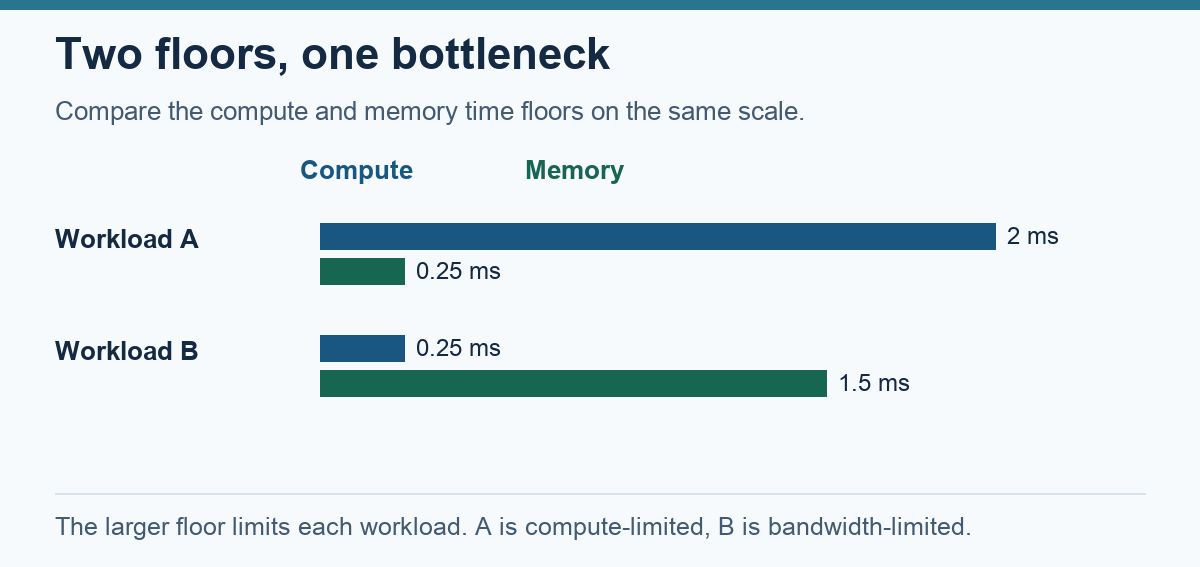

## Exercise map

| Exercise | What you will do | What to inspect |
| --- | --- | --- |
| 1. Calculate time floors | Compute the two resource times and identify the larger. | Which workload is limited by which resource? |
| 2. Change one resource | Try faster compute and faster memory separately. | Which intervention improves the modeled latency? |

In [ ]:
from math import isclose

peak = 60e12       # FLOP/s
bandwidth = 1e12  # bytes/s
workloads = {"A": (120e9, 0.25e9), "B": (15e9, 1.5e9)}

## Exercise 1. Calculate time floors

Return compute time, memory time, and their maximum, all in seconds. Predict which floor will dominate for workload A.

In [ ]:
def time_floors(operations, traffic_bytes, peak, bandwidth):
    return None

In [ ]:
a = time_floors(*workloads["A"], peak, bandwidth)
if a is not None:
    b = time_floors(*workloads["B"], peak, bandwidth)
    assert all(isclose(x, y) for x,y in zip(a,(.002,.00025,.002)))
    assert b[1] > b[0] and b[2] == b[1]
    for name, times in (("A", a), ("B", b)):
        print(name, "compute, memory, and floor (ms):", [round(t * 1000, 3) for t in times])
    print("PASS — different resources limit the two workloads")

## Exercise 2. Compare upgrades

Divide the original time floor by the new floor for an upgrade. For each workload, try doubling either resource. The inputs and amount of work stay fixed.

In [ ]:
def speedup(workload, compute_multiplier=1, bandwidth_multiplier=1):
    return None

In [ ]:
if a is not None and speedup(workloads["A"]) is not None:
    for name, workload in workloads.items():
        print(name, "compute upgrade:", speedup(workload, compute_multiplier=2),
              "bandwidth upgrade:", speedup(workload, bandwidth_multiplier=2))
    assert isclose(speedup(workloads["A"], compute_multiplier=2), 2)
    assert isclose(speedup(workloads["B"], compute_multiplier=2), 1)
    assert isclose(speedup(workloads["B"], bandwidth_multiplier=2), 2)
    print("PASS — an upgrade helps only when it lowers the larger floor")

## Wrap-up

Double compute and bandwidth together. Then keep the original device and halve workload B's traffic. Which change would you try first if the profiler also shows a large scheduling gap?